# Verifikasi implementasi

## Poin 1 — Pembaruan Q-value

Buat environment, lalu jalankan **satu langkah per cell** menggunakan `train_step()`
yang sama dengan training. Setiap langkah mencetak transisi, reward, dan persamaan Q
beserta angka yang digunakan. Tidak ada class tambahan atau helper notebook.

Contoh kecil: **0 → 1 → 2 → 0**, panjang ruas 1.700 + 1.700 + 1.600 = 5.000 m.
Terdapat dua action paralel 0 → 1 dengan skor berbeda agar epsilon-greedy punya pilihan.
Koordinat adalah posisi node dalam meter; panjang ruas adalah panjang perjalanan,
bukan jarak lurus. Graf dibuat sebagai `nx.MultiDiGraph`, kemudian action dibentuk
melalui `core.build_actions(G)`, sama seperti alur implementasi utama.
Setiap edge diisi `highway`, `surface`, dan `width`. Skor dihitung lewat
`core.add_comfort_scores(G)` sebelum `build_actions()`, seperti pada graf OSM.
Output langkah memperlihatkan asal skor dan kontribusi reward sebelum update Q.
Ini data sintetis untuk penelusuran, bukan snapshot OSM.

Jalankan dari root proyek dengan kernel **TA Rute Lari (Python 3.13)**.
Aturan 3 November: H/S/W: prioritas +1, lainnya mengikuti core, missing -0,5, bobot 0,55/0,30/0,15, tanpa
pengurangan 0,50. Arah 0,60; akses permissive -0,10/100 m; revisit -10;
sukses +100; seluruh kegagalan -50. comfort_score kini gabungan bertanda tanpa pembatasan rentang.


In [1]:
from collections import defaultdict
import importlib
import networkx as nx
import numpy as np
import rute_lari_core as core

core = importlib.reload(core)

verification_status = {}

In [2]:
# Graf sintetis terarah dengan ruas paralel, memakai koordinat meter.
G = nx.MultiDiGraph(crs="EPSG:32749")
G.add_node(0, x=700000.0, y=9195000.0)
G.add_node(1, x=701000.0, y=9195000.0)
G.add_node(2, x=700500.0, y=9195800.0)

# Isi atribut jalan; skor dihitung oleh core, tidak ditetapkan langsung.
G.add_edge(0, 1, key=0, length=1700.0, osmid=101,
           highway="residential", surface="asphalt", width="3")
G.add_edge(0, 1, key=1, length=1700.0, osmid=102,
           highway="service", surface="paving_stones", width="2")
G.add_edge(1, 2, key=0, length=1700.0, osmid=103,
           highway="residential", surface="asphalt", width="3")
G.add_edge(2, 0, key=0, length=1600.0, osmid=104,
           highway="residential", surface="asphalt", width="3")
core.add_comfort_scores(G)

# Action dibentuk oleh core, tanpa membuat EdgeAction sendiri.
actions_by_node = core.build_actions(G)
node_xy = {int(node): (data["x"], data["y"]) for node, data in G.nodes(data=True)}
env = core.RunningRouteEnvironment(0, "B", actions_by_node, node_xy)
q_table = defaultdict(dict)
rng = np.random.default_rng(0)
total_episodes = 2

# Q awal dapat diisi di sini; tanpa isian, nilainya dibaca nol.
# q_table[env.latest_state][(1, 0)] = 10.0
print(type(G).__name__, "| Node:", G.number_of_nodes(), "| Edge:", G.number_of_edges())
print("Action dari node 0:", [a.get_action_id() for a in actions_by_node[0]])
print("State awal:", env.latest_state)
for u, v, key, data in G.edges(keys=True, data=True):
    print(f"Edge {(u, v, key)}: {data['highway']}, {data['surface']}, "
          f"width={data['width']} m -> C={data['comfort_score']:.6f}")

MultiDiGraph | Node: 3 | Edge: 4
Action dari node 0: [(1, 0), (1, 1)]
State awal: (0, 0)
Edge (0, 1, 0): residential, asphalt, width=3 m -> C=1.000000
Edge (0, 1, 1): service, paving_stones, width=2 m -> C=-0.400000
Edge (1, 2, 0): residential, asphalt, width=3 m -> C=1.000000
Edge (2, 0, 0): residential, asphalt, width=3 m -> C=1.000000


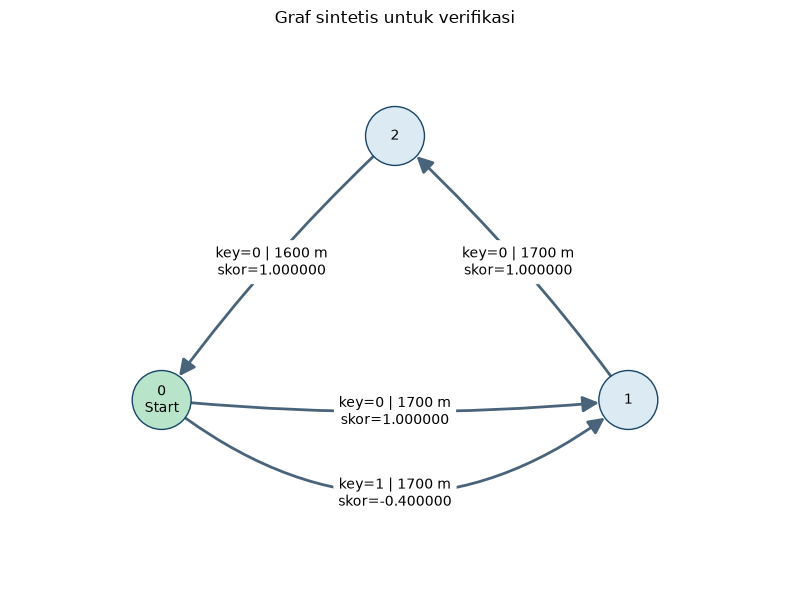

In [3]:
# Fungsi gambar bawaan NetworkX; lengkung memisahkan dua edge paralel.
import matplotlib.pyplot as plt

pos = {node: (data["x"], data["y"]) for node, data in G.nodes(data=True)}
curves = ["arc3,rad=0.05", "arc3,rad=0.40"]
edge_labels = {
    (u, v, key): f"key={key} | {data['length']:.0f} m\nskor={data['comfort_score']:.6f}"
    for u, v, key, data in G.edges(keys=True, data=True)
}

fig, ax = plt.subplots(figsize=(8, 6))
nx.draw_networkx(
    G, pos, ax=ax, arrows=True, arrowsize=24, node_size=1800,
    labels={0: "0\nStart", 1: "1", 2: "2"}, font_size=10,
    node_color=["#b8e4c9", "#dceaf3", "#dceaf3"],
    edgecolors="#194569", edge_color="#49647a", width=2,
    connectionstyle=curves,
)
nx.draw_networkx_edge_labels(
    G, pos, ax=ax, edge_labels=edge_labels, node_size=1800,
    connectionstyle=curves, rotate=False, font_size=10,
)
ax.set_title("Graf sintetis untuk verifikasi")
ax.margins(0.25)
ax.set_axis_off()
plt.tight_layout()
plt.show()

**Episode 1.** Reset environment dan hitung epsilon untuk episode berindeks 0.
Epsilon tetap sama untuk ketiga langkah. Action tidak dipaksa agar epsilon-greedy digunakan.

In [4]:
episode = 0
env.reset()
epsilon = core.epsilon_for_episode(episode, total_episodes)
print("Episode:", episode + 1, "| Epsilon:", epsilon)
print("State awal:", env.latest_state)

Episode: 1 | Epsilon: 1.0
State awal: (0, 0)


In [5]:
# Langkah 1 — lanjutkan environment dan Q-table yang sama.
result = core.train_step(env, q_table, rng, epsilon, verbose=True)

Langkah       : 1
Epsilon       : 1.0
State sebelum : (0, 0)
Action legal  : [(1, 0), (1, 1)]
Action dipilih: (1, 1)
State sesudah : (1, 4)
Jarak total   : 1700.0 m
Data jalan    : highway=service, surface=paving_stones, width=2, access=None
Skor atribut  : H=-1.0, S=1.0, W=-1.0
C = 0.55 * -1.0 + 0.3 * 1.0 + 0.15 * -1.0 = -0.4
R ruas = -0.4 * (1700.0 / 100) = -6.800000000000001
R akses       : 0.0
Jarak lurus ke start: 0.0 -> 1000.0 m
R arah        : 0.0 (tidak diterapkan)
R revisit     : 0.0
R terminasi   : 0.0 (running)
R total = -6.800000000000001 + 0.0 + 0.0 + 0.0 + 0.0 + 0.0 = -6.800000000000001
Reward langkah: -6.800000000000001
Penalti buntu : 0.0
Reward untuk Q: -6.800000000000001
Selesai       : False (running)
Q sebelum     : 0.0
Max Q berikut : 0.0
Alpha / Gamma : 0.15 / 0.95
Target Q      : -6.800000000000001
TD-error      : -6.800000000000001
Q baru = 0.0 + 0.15 * [-6.800000000000001 + 0.95 * 0.0 - 0.0]
       = -1.02


In [6]:
# Langkah 2 — lanjutkan environment dan Q-table yang sama.
result = core.train_step(env, q_table, rng, epsilon, verbose=True)

Langkah       : 2
Epsilon       : 1.0
State sebelum : (1, 4)
Action legal  : [(2, 0)]
Action dipilih: (2, 0)
State sesudah : (2, 9)
Jarak total   : 3400.0 m
Data jalan    : highway=residential, surface=asphalt, width=3, access=None
Skor atribut  : H=1.0, S=1.0, W=1.0
C = 0.55 * 1.0 + 0.3 * 1.0 + 0.15 * 1.0 = 1.0
R ruas = 1.0 * (1700.0 / 100) = 17.0
R akses       : 0.0
Jarak lurus ke start: 1000.0 -> 943.3981132056604 m
R arah        : -0.33961132076603784 (penalti fase awal)
R arah = -0.6 * (1000.0 - 943.3981132056604) / 100 = -0.33961132076603784
R revisit     : 0.0
R terminasi   : 0.0 (running)
R total = 17.0 + 0.0 + -0.33961132076603784 + 0.0 + 0.0 + 0.0 = 16.66038867923396
Reward langkah: 16.66038867923396
Penalti buntu : 0.0
Reward untuk Q: 16.66038867923396
Selesai       : False (running)
Q sebelum     : 0.0
Max Q berikut : 0.0
Alpha / Gamma : 0.15 / 0.95
Target Q      : 16.66038867923396
TD-error      : 16.66038867923396
Q baru = 0.0 + 0.15 * [16.66038867923396 + 0.95 * 0.0 - 0.

In [7]:
# Langkah 3 — lanjutkan environment dan Q-table yang sama.
result = core.train_step(env, q_table, rng, epsilon, verbose=True)

Langkah       : 3
Epsilon       : 1.0
State sebelum : (2, 9)
Action legal  : [(0, 0)]
Action dipilih: (0, 0)
State sesudah : (0, 14)
Jarak total   : 5000.0 m
Data jalan    : highway=residential, surface=asphalt, width=3, access=None
Skor atribut  : H=1.0, S=1.0, W=1.0
C = 0.55 * 1.0 + 0.3 * 1.0 + 0.15 * 1.0 = 1.0
R ruas = 1.0 * (1600.0 / 100) = 16.0
R akses       : 0.0
Jarak lurus ke start: 943.3981132056604 -> 0.0 m
R arah        : 0.0 (tidak diterapkan)
R revisit     : 0.0
R terminasi   : 100.0 (success)
R total = 16.0 + 0.0 + 0.0 + 0.0 + 100.0 + 0.0 = 116.0
Reward langkah: 116.0
Penalti buntu : 0.0
Reward untuk Q: 116.0
Selesai       : True (success)
Q sebelum     : 0.0
Max Q berikut : 0.0
Alpha / Gamma : 0.15 / 0.95
Target Q      : 116.0
TD-error      : 116.0
Q baru = 0.0 + 0.15 * [116.0 + 0.95 * 0.0 - 0.0]
       = 17.4


**Episode 2.** Environment di-reset, sedangkan Q-table dan generator acak diteruskan,
sama seperti training. Epsilon dihitung lagi untuk episode berindeks 1.
Pada contoh dua episode ini, epsilon berubah dari **1,00** menjadi **0,05**.

In [8]:
episode = 1
env.reset()
epsilon = core.epsilon_for_episode(episode, total_episodes)
print("Episode:", episode + 1, "| Epsilon:", epsilon)
print("State awal:", env.latest_state)
print("Q-table dari episode sebelumnya:", dict(q_table))

Episode: 2 | Epsilon: 0.05
State awal: (0, 0)
Q-table dari episode sebelumnya: {(1, 4): {(2, 0): 2.499058301885094}, (0, 0): {(1, 1): -1.02}, (2, 9): {(0, 0): 17.4}}


In [9]:
# Langkah 1 — epsilon tetap sepanjang episode ini.
result = core.train_step(env, q_table, rng, epsilon, verbose=True)

Langkah       : 1
Epsilon       : 0.05
State sebelum : (0, 0)
Action legal  : [(1, 0), (1, 1)]
Action dipilih: (1, 0)
State sesudah : (1, 4)
Jarak total   : 1700.0 m
Data jalan    : highway=residential, surface=asphalt, width=3, access=None
Skor atribut  : H=1.0, S=1.0, W=1.0
C = 0.55 * 1.0 + 0.3 * 1.0 + 0.15 * 1.0 = 1.0
R ruas = 1.0 * (1700.0 / 100) = 17.0
R akses       : 0.0
Jarak lurus ke start: 0.0 -> 1000.0 m
R arah        : 0.0 (tidak diterapkan)
R revisit     : 0.0
R terminasi   : 0.0 (running)
R total = 17.0 + 0.0 + 0.0 + 0.0 + 0.0 + 0.0 = 17.0
Reward langkah: 17.0
Penalti buntu : 0.0
Reward untuk Q: 17.0
Selesai       : False (running)
Q sebelum     : 0.0
Max Q berikut : 2.499058301885094
Alpha / Gamma : 0.15 / 0.95
Target Q      : 19.374105386790838
TD-error      : 19.374105386790838
Q baru = 0.0 + 0.15 * [17.0 + 0.95 * 2.499058301885094 - 0.0]
       = 2.9061158080186256


In [10]:
# Langkah 2 — epsilon tetap sepanjang episode ini.
result = core.train_step(env, q_table, rng, epsilon, verbose=True)

Langkah       : 2
Epsilon       : 0.05
State sebelum : (1, 4)
Action legal  : [(2, 0)]
Action dipilih: (2, 0)
State sesudah : (2, 9)
Jarak total   : 3400.0 m
Data jalan    : highway=residential, surface=asphalt, width=3, access=None
Skor atribut  : H=1.0, S=1.0, W=1.0
C = 0.55 * 1.0 + 0.3 * 1.0 + 0.15 * 1.0 = 1.0
R ruas = 1.0 * (1700.0 / 100) = 17.0
R akses       : 0.0
Jarak lurus ke start: 1000.0 -> 943.3981132056604 m
R arah        : -0.33961132076603784 (penalti fase awal)
R arah = -0.6 * (1000.0 - 943.3981132056604) / 100 = -0.33961132076603784
R revisit     : 0.0
R terminasi   : 0.0 (running)
R total = 17.0 + 0.0 + -0.33961132076603784 + 0.0 + 0.0 + 0.0 = 16.66038867923396
Reward langkah: 16.66038867923396
Penalti buntu : 0.0
Reward untuk Q: 16.66038867923396
Selesai       : False (running)
Q sebelum     : 2.499058301885094
Max Q berikut : 17.4
Alpha / Gamma : 0.15 / 0.95
Target Q      : 33.19038867923396
TD-error      : 30.69133037734887
Q baru = 2.499058301885094 + 0.15 * [16.66

In [11]:
# Langkah 3 — epsilon tetap sepanjang episode ini.
result = core.train_step(env, q_table, rng, epsilon, verbose=True)

Langkah       : 3
Epsilon       : 0.05
State sebelum : (2, 9)
Action legal  : [(0, 0)]
Action dipilih: (0, 0)
State sesudah : (0, 14)
Jarak total   : 5000.0 m
Data jalan    : highway=residential, surface=asphalt, width=3, access=None
Skor atribut  : H=1.0, S=1.0, W=1.0
C = 0.55 * 1.0 + 0.3 * 1.0 + 0.15 * 1.0 = 1.0
R ruas = 1.0 * (1600.0 / 100) = 16.0
R akses       : 0.0
Jarak lurus ke start: 943.3981132056604 -> 0.0 m
R arah        : 0.0 (tidak diterapkan)
R revisit     : 0.0
R terminasi   : 100.0 (success)
R total = 16.0 + 0.0 + 0.0 + 0.0 + 100.0 + 0.0 = 116.0
Reward langkah: 116.0
Penalti buntu : 0.0
Reward untuk Q: 116.0
Selesai       : True (success)
Q sebelum     : 17.4
Max Q berikut : 0.0
Alpha / Gamma : 0.15 / 0.95
Target Q      : 116.0
TD-error      : 98.6
Q baru = 17.4 + 0.15 * [116.0 + 0.95 * 0.0 - 17.4]
       = 32.19


**Cara membaca hasil terbaru**

Residential/asphalt/width 3 m: $r_H=r_S=r_W=1$, sehingga $B=1$.
Service/paving_stones/width 2 m: $r_H=-1,r_S=1,r_W=-1$, sehingga
$B=-0{,}55+0{,}30-0{,}15=-0{,}40$.

Pada langkah pertama episode 1, Q masih nol. Key 0 memberi reward ruas
$1\times1700/100=17$ dan Q baru $0{,}15(17)=2{,}55$.
Key 1 memberi reward ruas $-0{,}40\times1700/100=-6{,}80$ dan Q baru $-1{,}02$.
Arah/revisit/akses/terminal pada langkah pertama nol. Pada langkah kedua terdapat
penalti arah fase awal berskala 0,60; penutupan loop memberi bonus +100.

Output berasal dari train_step/step yang sama dengan training. result menyimpan
angka aktual dan env.latest_state membaca state terbaru. Action manual dapat
diisi melalui parameter action; epsilon tidak memengaruhi action yang dipaksa.
Reset episode mempertahankan Q-table/RNG; ulangi cell environment untuk mulai nol.
Angka harapan berikutnya ditulis independen dari hasil fungsi yang diuji.


## Verifikasi pada graf OSM penelitian

Bagian ini menelusuri **tiga langkah awal satu episode** pada snapshot lokal yang sama
dengan penelitian. Graf, environment, Q-table, dan RNG memakai variabel sendiri agar
contoh sintetis tetap terpisah. Tidak mengunduh atau menyimpan ulang GraphML.

Alurnya: muat snapshot → `add_comfort_scores()` → `build_actions()` → environment →
`train_step()`. Ketiga langkah memakai epsilon yang sama dari `epsilon_for_episode()`.
Ini penelusuran singkat untuk memeriksa integrasi dan Q-value, bukan evaluasi keberhasilan loop.

In [12]:
# Wajib memakai snapshot lokal; hentikan sebelum fungsi loader jika belum tersedia.
if not core.GRAPH_PATH.is_file():
    raise FileNotFoundError("Snapshot graf belum ada. Jalankan analisa.ipynb terlebih dahulu.")

G_osm, start_osm, graph_path_osm, _ = core.load_or_download_graph()
core.add_comfort_scores(G_osm)
actions_osm = core.build_actions(G_osm)
node_xy_osm = {int(node): (data["x"], data["y"]) for node, data in G_osm.nodes(data=True)}
env_osm = core.RunningRouteEnvironment(start_osm, "B", actions_osm, node_xy_osm)
q_table_osm = defaultdict(dict)
rng_osm = np.random.default_rng(0)
epsilon_osm = core.epsilon_for_episode(episode=0, total_episodes=2)

print("Snapshot:", graph_path_osm)
print("Node:", len(G_osm), "| Edge:", G_osm.number_of_edges())
print("CRS:", G_osm.graph["crs"])
print("Start:", start_osm, "| State awal:", env_osm.latest_state)
print("Episode: 1 | Epsilon:", epsilon_osm)

Snapshot: /Users/david/widya_kartika/uwika-ta-31123022-2026/data_osm_5km/graf_jalan_kaki_5km.graphml
Node: 8027 | Edge: 21374
CRS: EPSG:32749
Start: 1720975931 | State awal: (1720975931, 0)
Episode: 1 | Epsilon: 1.0


In [13]:
# Langkah OSM 1. Simpan hasil pertama untuk dibandingkan dengan hitungan manual.
result_osm = core.train_step(env_osm, q_table_osm, rng_osm, epsilon_osm, verbose=True)
first_osm_result = result_osm.copy()
u_osm = result_osm["state"][0]
v_osm, key_osm = result_osm["action_id"]
print("Edge (u, v, key):", (u_osm, v_osm, key_osm))
print("Atribut edge:", {
    name: G_osm[u_osm][v_osm][key_osm].get(name)
    for name in ("osmid", "highway", "surface", "width", "access", "length", "comfort_score")
})

Langkah       : 1
Epsilon       : 1.0
State sebelum : (1720975931, 0)
Action legal  : [(311432333, 0), (1720975893, 0), (1720975897, 0)]
Action dipilih: (1720975893, 0)
State sesudah : (1720975893, 0)
Jarak total   : 157.32164137901165 m
Data jalan    : highway=residential, surface=paving_stones, width=4, access=permissive
Skor atribut  : H=1.0, S=1.0, W=1.0
C = 0.55 * 1.0 + 0.3 * 1.0 + 0.15 * 1.0 = 1.0
R ruas = 1.0 * (157.32164137901165 / 100) = 1.5732164137901166
R akses = -0.1 * (157.32164137901165 / 100) = -0.15732164137901164
Jarak lurus ke start: 0.0 -> 157.4080198207155 m
R arah        : 0.0 (tidak diterapkan)
R revisit     : 0.0
R terminasi   : 0.0 (running)
R total = 1.5732164137901166 + -0.15732164137901164 + 0.0 + 0.0 + 0.0 + 0.0 = 1.4158947724111048
Reward langkah: 1.4158947724111048
Penalti buntu : 0.0
Reward untuk Q: 1.4158947724111048
Selesai       : False (running)
Q sebelum     : 0.0
Max Q berikut : 0.0
Alpha / Gamma : 0.15 / 0.95
Target Q      : 1.4158947724111048
TD-

In [14]:
# Langkah OSM 2. Lanjutkan episode, Q-table, RNG, dan epsilon yang sama.
if env_osm.done:
    print("Episode sudah selesai:", env_osm.termination_reason)
else:
    result_osm = core.train_step(env_osm, q_table_osm, rng_osm, epsilon_osm, verbose=True)
    print("Edge (u, v, key):", (result_osm["state"][0], *result_osm["action_id"]))

Langkah       : 2
Epsilon       : 1.0
State sebelum : (1720975893, 0)
Action legal  : [(1720975891, 0), (5589608591, 0)]
Action dipilih: (1720975891, 0)
State sesudah : (1720975891, 0)
Jarak total   : 195.54712397035394 m
Data jalan    : highway=tertiary, surface=asphalt, width=4, access=None
Skor atribut  : H=1.0, S=1.0, W=1.0
C = 0.55 * 1.0 + 0.3 * 1.0 + 0.15 * 1.0 = 1.0
R ruas = 1.0 * (38.2254825913423 / 100) = 0.38225482591342297
R akses       : 0.0
Jarak lurus ke start: 157.4080198207155 -> 162.5717650296929 m
R arah        : 0.0 (tidak diterapkan)
R revisit     : 0.0
R terminasi   : 0.0 (running)
R total = 0.38225482591342297 + 0.0 + 0.0 + 0.0 + 0.0 + 0.0 = 0.38225482591342297
Reward langkah: 0.38225482591342297
Penalti buntu : 0.0
Reward untuk Q: 0.38225482591342297
Selesai       : False (running)
Q sebelum     : 0.0
Max Q berikut : 0.0
Alpha / Gamma : 0.15 / 0.95
Target Q      : 0.38225482591342297
TD-error      : 0.38225482591342297
Q baru = 0.0 + 0.15 * [0.38225482591342297 +

In [15]:
# Langkah OSM 3. Lanjutkan episode, Q-table, RNG, dan epsilon yang sama.
if env_osm.done:
    print("Episode sudah selesai:", env_osm.termination_reason)
else:
    result_osm = core.train_step(env_osm, q_table_osm, rng_osm, epsilon_osm, verbose=True)
    print("Edge (u, v, key):", (result_osm["state"][0], *result_osm["action_id"]))

Langkah       : 3
Epsilon       : 1.0
State sebelum : (1720975891, 0)
Action legal  : [(311431486, 0), (1720975897, 0)]
Action dipilih: (311431486, 0)
State sesudah : (311431486, 0)
Jarak total   : 244.05318127767396 m
Data jalan    : highway=tertiary, surface=asphalt, width=4, access=None
Skor atribut  : H=1.0, S=1.0, W=1.0
C = 0.55 * 1.0 + 0.3 * 1.0 + 0.15 * 1.0 = 1.0
R ruas = 1.0 * (48.506057307320035 / 100) = 0.48506057307320033
R akses       : 0.0
Jarak lurus ke start: 162.5717650296929 -> 181.63893400846408 m
R arah        : 0.0 (tidak diterapkan)
R revisit     : 0.0
R terminasi   : 0.0 (running)
R total = 0.48506057307320033 + 0.0 + 0.0 + 0.0 + 0.0 + 0.0 = 0.48506057307320033
Reward langkah: 0.48506057307320033
Penalti buntu : 0.0
Reward untuk Q: 0.48506057307320033
Selesai       : False (running)
Q sebelum     : 0.0
Max Q berikut : 0.0
Alpha / Gamma : 0.15 / 0.95
Target Q      : 0.48506057307320033
TD-error      : 0.48506057307320033
Q baru = 0.0 + 0.15 * [0.48506057307320033 +

**Perhitungan manual untuk langkah OSM pertama**

Snapshot/seed 0 memilih edge **(1720975931, 1720975893, 0)**:
residential, paving_stones, width 4 m, access permissive, panjang
**157,32164137901165 m**. Ketiga reward dasar bernilai +1, sehingga $B=1$.

Reward ruas $=1\times157{,}32164137901165/100$.
Reward akses $=-0{,}10\times157{,}32164137901165/100$.
Arah/revisit/terminal/buntu nol pada langkah awal ini. Maka total reward
$=0{,}90\times157{,}32164137901165/100\approx1{,}415894772411105$.

Dengan Q awal dan next Q nol, Q baru $=0{,}15R\approx0{,}212384215861666$.
Acuan memakai atribut dan angka literal, bukan hasil fungsi reward yang diuji.
Jika snapshot berubah, tinjau kembali identitas edge dan hitungan ini.


In [16]:
import math

# Acuan dari angka pada penjelasan manual, bukan dari result hasil fungsi yang diuji.
manual_reward_osm = (1.0 - 0.10) * 157.32164137901165 / 100
manual_q_osm = 0.0 + 0.15 * (manual_reward_osm + 0.95 * 0.0 - 0.0)
observed_edge_osm = (first_osm_result["state"][0], *first_osm_result["action_id"])

assert observed_edge_osm == (1720975931, 1720975893, 0), "Edge berubah; tinjau contoh manual."
assert first_osm_result["q_before"] == 0 and first_osm_result["max_next_q"] == 0
print("Reward manual:", manual_reward_osm, "| Reward core:", first_osm_result["reward"])
print("Q manual:", manual_q_osm, "| Q core:", first_osm_result["q_after"])
print("Selisih Q:", first_osm_result["q_after"] - manual_q_osm)
assert math.isclose(first_osm_result["reward"], manual_reward_osm, rel_tol=0, abs_tol=1e-9)
assert math.isclose(first_osm_result["q_after"], manual_q_osm, rel_tol=0, abs_tol=1e-9)
assert math.isclose(
    q_table_osm[first_osm_result["state"]][first_osm_result["action_id"]],
    manual_q_osm, rel_tol=0, abs_tol=1e-9,
)
print("LULUS — perhitungan manual langkah OSM pertama sesuai dengan core dan Q-table.")
verification_status[1] = True
# Bootstrap nonterminal harus memakai next Q legal yang tidak nol.
manual_env = core.RunningRouteEnvironment(0,"B",actions_by_node,node_xy)
manual_q = defaultdict(dict)
manual_q[(0,0)][(1,0)] = 2.0
manual_q[(1,4)][(2,0)] = 4.0
manual_q[(1,4)][(0,99)] = 1000.0  # action ilegal, tidak boleh masuk bootstrap
chosen = next(a for a in manual_env.available_actions() if a.get_action_id()==(1,0))
manual_nonterminal = core.train_step(manual_env,manual_q,np.random.default_rng(0),0,action=chosen)
assert math.isclose(manual_nonterminal["q_after"],2+0.15*(17+0.95*4-2),abs_tol=1e-9)
assert manual_nonterminal["max_next_q"]==4.0
# Terminal tidak mengambil next Q meskipun sengaja diberi nilai besar.
chosen = next(a for a in manual_env.available_actions() if a.get_action_id()==(2,0))
core.train_step(manual_env,manual_q,np.random.default_rng(0),0,action=chosen)
manual_q[(2,9)][(0,0)] = 2.0
manual_q[(0,14)][(1,0)] = 1000.0
chosen = next(a for a in manual_env.available_actions() if a.get_action_id()==(0,0))
manual_terminal = core.train_step(manual_env,manual_q,np.random.default_rng(0),0,action=chosen)
assert manual_terminal["max_next_q"]==0 and math.isclose(manual_terminal["reward"],116,abs_tol=1e-9)
assert math.isclose(manual_terminal["q_after"],2+0.15*(116-2),abs_tol=1e-9)
print("LULUS — hitungan nonterminal dengan bootstrap legal dan terminal tanpa bootstrap.")


Reward manual: 1.415894772411105 | Reward core: 1.4158947724111048
Q manual: 0.21238421586166575 | Q core: 0.21238421586166573
Selisih Q: -2.7755575615628914e-17
LULUS — perhitungan manual langkah OSM pertama sesuai dengan core dan Q-table.
LULUS — hitungan nonterminal dengan bootstrap legal dan terminal tanpa bootstrap.


Untuk mengulang bagian OSM dari nol, jalankan kembali cell pemuatan snapshot, lalu
cell langkah-langkahnya. Bagian ini berhenti diamati setelah tiga langkah; itu bukan
terminasi episode. Tidak perlu menutup loop untuk pemeriksaan perhitungan ini.
Hasilnya belum membuktikan seluruh jaringan atau kondisi jalan di lapangan valid.

## Poin 2 — Transisi state dan action mask

Acuan untuk lintasan 0 → 1 → 2 → 0 (key 0): jarak kumulatif **1.700, 3.400,
5.000 m**, dengan indeks progres **4, 9, 14**. State A hanya menyimpan posisi;
B menambahkan indeks progres; C juga menyimpan node sebelumnya. Setiap kasus
membuat environment/Q-table sendiri dan menjalankan fungsi core yang sama.

Cell ini memakai langkah terkontrol untuk membandingkan **actual** dan **expected**.
Ini memeriksa isi state yang dikirim ke Q-table. Action mask dan reward memang
memakai jarak/riwayat environment untuk semua skenario; kelulusan tidak berarti
state A–C memuat seluruh kondisi environment atau menjamin sifat Markov.

In [17]:
import pandas as pd
from IPython.display import display

state_rows = []
expected_states = {
    "A": [(1,), (2,), (0,)],
    "B": [(1, 4), (2, 9), (0, 14)],
    "C": [(1, 0, 4), (2, 1, 9), (0, 2, 14)],
}
for scenario in ("A", "B", "C"):
    test_env = core.RunningRouteEnvironment(0, scenario, actions_by_node, node_xy)
    expected_reset = {"A": (0,), "B": (0, 0), "C": (0, -1, 0)}[scenario]
    assert test_env.latest_state == expected_reset
    test_q = defaultdict(dict)
    for index, action_id in enumerate(((1, 0), (2, 0), (0, 0))):
        chosen = next(a for a in test_env.available_actions() if a.get_action_id() == action_id)
        observed = core.train_step(test_env, test_q, np.random.default_rng(0), 0, action=chosen)
        expected = expected_states[scenario][index]
        assert observed["next_state"] == test_env.latest_state == expected
        assert test_env.total_distance_m == (1700, 3400, 5000)[index]
        assert test_env.previous_node == (0, 1, 2)[index]
        state_rows.append({"state": scenario, "langkah": index+1,
                           "actual": observed["next_state"], "expected": expected,
                           "jarak_m": test_env.total_distance_m, "hasil": "LULUS"})
    assert all(len(key) == {"A":1, "B":2, "C":3}[scenario] for key in test_q)
    assert dict(test_env.node_visits) == {0:2, 1:1, 2:1}
    assert test_env.reset() == expected_reset
    assert test_env.total_distance_m == test_env.step_count == 0
    assert dict(test_env.node_visits) == {0:1}
display(pd.DataFrame(state_rows))
print("LULUS — state A/B/C, previous_node, jarak, kunjungan, dan reset.")

,state,langkah,actual,expected,jarak_m,hasil
0,A,1,"(1,)","(1,)",1700.0,LULUS
1,A,2,"(2,)","(2,)",3400.0,LULUS
2,A,3,"(0,)","(0,)",5000.0,LULUS
3,B,1,"(1, 4)","(1, 4)",1700.0,LULUS
4,B,2,"(2, 9)","(2, 9)",3400.0,LULUS
5,B,3,"(0, 14)","(0, 14)",5000.0,LULUS
6,C,1,"(1, 0, 4)","(1, 0, 4)",1700.0,LULUS
7,C,2,"(2, 1, 9)","(2, 1, 9)",3400.0,LULUS
8,C,3,"(0, 2, 14)","(0, 2, 14)",5000.0,LULUS


LULUS — state A/B/C, previous_node, jarak, kunjungan, dan reset.


**Batas kategori jarak.** Untuk mengisolasi `progress_bin()`, cell berikut hanya
mengisi `total_distance_m`. Ini pengujian properti kategori, bukan simulasi perjalanan
atau bukti panjang rute. Acuan kategori ditulis langsung dari rentang 0–5.500 m,
16 kategori, dan pembatas indeks maksimum 15.

In [18]:
bin_env = core.RunningRouteEnvironment(0, "B", actions_by_node, node_xy)
bin_rows = []
for distance, expected in ((0,0), (343.749,0), (343.75,1), (2499.99,7),
                           (2500,7), (2750,8), (5000,14), (5499.999,15),
                           (5500,15), (6000,15)):
    bin_env.total_distance_m = distance
    actual = bin_env.progress_bin()
    assert actual == expected
    assert bin_env.latest_state == (0, expected)
    bin_rows.append({"jarak_m":distance,"actual":actual,"expected":expected,"hasil":"LULUS"})
display(pd.DataFrame(bin_rows))

,jarak_m,actual,expected,hasil
0,0.000,0,0,LULUS
1,343.749,0,0,LULUS
2,343.750,1,1,LULUS
3,2499.990,7,7,LULUS
4,2500.000,7,7,LULUS
5,2750.000,8,8,LULUS
6,5000.000,14,14,LULUS
7,5499.999,15,15,LULUS
8,5500.000,15,15,LULUS
9,6000.000,15,15,LULUS


**Action mask.** Graf kecil berikut memungkinkan jalur 0 → 2 → 1. Saat di node 1,
node 2 sudah pernah dikunjungi, node 3 masih baru, dan ada ruas menuju start.
Sebelum 2.500 m, revisit ditutup; tepat 2.500 m, dua key menuju node 2 boleh dipilih
bersama fresh/closing action. Setelah node 2 dikunjungi dua kali, keduanya ditutup.
Seluruh kondisi dicapai dengan langkah sungguhan, tanpa mengubah catatan kunjungan.

In [19]:
road_test = {"highway":"residential", "surface":"asphalt", "width":"3"}
G_mask = nx.MultiDiGraph(crs="EPSG:32749")
G_mask.add_nodes_from([(0,{"x":0.,"y":0.}), (1,{"x":200.,"y":0.}),
                       (2,{"x":100.,"y":0.}), (3,{"x":300.,"y":0.})])
for u,v,key,length in ((0,2,0,1200), (2,1,0,1300), (1,2,0,100),
                        (1,2,1,150), (1,3,0,100), (1,0,0,3000)):
    G_mask.add_edge(u,v,key=key,length=length,**road_test)
mask_xy = {n:(d["x"],d["y"]) for n,d in G_mask.nodes(data=True)}
mask_rows = []
mask_envs = {}
for before_distance, second_length, expected in (
    (2499,1299,{(3,0),(0,0)}),
    (2500,1300,{(2,0),(2,1),(3,0),(0,0)}),
):
    case_graph = G_mask.copy()
    case_graph[2][1][0]["length"] = second_length
    core.add_comfort_scores(case_graph)
    case_actions = core.build_actions(case_graph)
    case_env = core.RunningRouteEnvironment(0,"B",case_actions,mask_xy)
    for action_id in ((2,0),(1,0)):
        chosen = next(a for a in case_env.available_actions() if a.get_action_id()==action_id)
        core.train_step(case_env,defaultdict(dict),np.random.default_rng(0),0,action=chosen)
    actual = {a.get_action_id() for a in case_env.available_actions()}
    assert case_env.total_distance_m == before_distance
    assert actual == expected
    mask_envs[before_distance] = case_env
    mask_rows.append({"kondisi":f"jarak {before_distance} m", "actual":sorted(actual),
                      "expected":sorted(expected), "hasil":"LULUS"})

case_env = mask_envs[2500]
for action_id in ((2,0),(1,0)):
    chosen = next(a for a in case_env.available_actions() if a.get_action_id()==action_id)
    core.train_step(case_env,defaultdict(dict),np.random.default_rng(0),0,action=chosen)
actual = {a.get_action_id() for a in case_env.available_actions()}
assert case_env.node_visits[2] == 2 and actual == {(3,0)}
mask_rows.append({"kondisi":"node 2 sudah dua kunjungan", "actual":sorted(actual),
                  "expected":[(3,0)], "hasil":"LULUS"})
display(pd.DataFrame(mask_rows))

,kondisi,actual,expected,hasil
0,jarak 2499 m,"[(0, 0), (3, 0)]","[(0, 0), (3, 0)]",LULUS
1,jarak 2500 m,"[(0, 0), (2, 0), (2, 1), (3, 0)]","[(0, 0), (2, 0), (2, 1), (3, 0)]",LULUS
2,node 2 sudah dua kunjungan,"[(3, 0)]","[(3, 0)]",LULUS


In [20]:
# Action yang diblokir tidak dapat dijalankan langsung melalui step().
case_env = mask_envs[2499]
blocked = next(a for a in case_env.actions_by_node[1] if a.get_action_id()==(2,0))
before_position = (case_env.latest_state, case_env.total_distance_m, list(case_env.path_nodes))
try:
    case_env.step(blocked)
except ValueError as error:
    print("Penolakan yang diharapkan:", error)
else:
    raise AssertionError("Action revisit sebelum 2.500 m seharusnya ditolak.")
assert (case_env.latest_state,case_env.total_distance_m,case_env.path_nodes) == before_position

# Q tinggi pada action terlarang tidak boleh mengalahkan action legal saat greedy.
legal_actions = case_env.available_actions()
legal_ids = {a.get_action_id() for a in legal_actions}
choice_q = defaultdict(dict)
choice_q[case_env.latest_state] = {(2,0):1000., (3,0):1., (0,0):0.}
for test_epsilon in (0.0,1.0):
    choice_rng = np.random.default_rng(0)
    selected_ids = [core.choose_action(choice_q,case_env.latest_state,legal_actions,
                                      choice_rng,test_epsilon).get_action_id() for _ in range(20)]
    assert set(selected_ids) <= legal_ids
    if test_epsilon == 0:
        assert set(selected_ids) == {(3,0)}
    print("Epsilon:",test_epsilon,"| Action terpilih:",sorted(set(selected_ids)))
verification_status[2] = True
print("LULUS — aksi ilegal ditolak; eksplorasi dan greedy hanya memilih aksi legal.")
# Access diperiksa pada build_actions; highway non-prioritas tetap menjadi action.
access_cases = [(None,True),("yes",True),("permissive",True),("no",False),
                ("private",False),("destination",False),("unknown",False),
                (["yes","permissive"],True),("yes;private",False),
                ("['yes', 'permissive']",True)]
for value,allowed in access_cases:
    access_graph=nx.MultiDiGraph(crs="EPSG:32749")
    access_graph.add_edge(0,1,key=0,length=100.,highway="service",
                          surface="asphalt",width="3",access=value)
    core.add_comfort_scores(access_graph)
    assert bool(core.build_actions(access_graph).get(0))==allowed
print("LULUS — whitelist access dan service tetap legal bila akses diizinkan.")


Penolakan yang diharapkan: Action tidak legal untuk state environment saat ini.
Epsilon: 0.0 | Action terpilih: [(3, 0)]
Epsilon: 1.0 | Action terpilih: [(0, 0), (3, 0)]
LULUS — aksi ilegal ditolak; eksplorasi dan greedy hanya memilih aksi legal.
LULUS — whitelist access dan service tetap legal bila akses diizinkan.


## Poin 3 — Konsistensi graf dan akumulasi jarak

Pemeriksaan snapshot penuh mencakup CRS meter, koordinat, panjang positif/berhingga,
serta kecocokan seluruh action dengan edge `(u,v,key)`. Untuk edge yang memiliki
geometri, ujung geometri harus sesuai kedua node (boleh urutan terbalik), toleransi
0,1 m. Edge tanpa geometri eksplisit tetap boleh dipakai; jangan menafsirkan panjang
jalan sebagai jarak lurus antar-node.

Kelulusan memeriksa konsistensi data yang tersimpan, bukan apakah jalan terbuka
atau benar-benar dapat dilalui saat ini. Itu perlu validasi lapangan.

In [21]:
from pyproj import CRS

crs_osm = CRS.from_user_input(G_osm.graph["crs"])
assert isinstance(G_osm,nx.MultiDiGraph) and crs_osm.is_projected
assert all(math.isclose(axis.unit_conversion_factor,1.0) for axis in crs_osm.axis_info[:2])
assert all(np.isfinite([data["x"],data["y"]]).all() for _,data in G_osm.nodes(data=True))
assert start_osm in G_osm
assert all(math.isfinite(float(data["length"])) and float(data["length"])>0
           for *_,data in G_osm.edges(keys=True,data=True))

geometry_issues = []
geometry_count = 0
for u,v,key,data in G_osm.edges(keys=True,data=True):
    geometry = data.get("geometry")
    if geometry is None:
        continue
    geometry_count += 1
    if geometry.geom_type != "LineString" or not geometry.is_valid:
        geometry_issues.append((u,v,key,"geometri tidak sesuai"))
        continue
    ends = np.array([geometry.coords[0][:2],geometry.coords[-1][:2]])
    nodes = np.array([node_xy_osm[u],node_xy_osm[v]])
    if not (np.allclose(ends,nodes,rtol=0,atol=.1) or
            np.allclose(ends,nodes[::-1],rtol=0,atol=.1)):
        geometry_issues.append((u,v,key,"ujung geometri tidak cocok"))
assert not geometry_issues, geometry_issues[:5]

# Snapshot tetap 21.374 edge, 74 dikeluarkan karena access destination/no.
assert G_osm.number_of_edges()==21374
assert sum(len(items) for items in actions_osm.values()) == 21300
for u,items in actions_osm.items():
    for action in items:
        assert G_osm.has_edge(u,action.next_node,action.key)
        edge = G_osm[u][action.next_node][action.key]
        assert action.length_m == edge["length"]
        assert action.comfort_score == edge["comfort_score"]
print("LULUS —",len(G_osm),"node,",G_osm.number_of_edges(),"edge; action legal:",sum(map(len,actions_osm.values())))
print("geometri eksplisit diperiksa:",geometry_count,"| CRS:",crs_osm.to_string())

LULUS — 8027 node, 21374 edge; action legal: 21300
geometri eksplisit diperiksa: 10214 | CRS: EPSG:32749


In [22]:
# Bedakan panjang dua edge paralel dan periksa jarak tiap langkah secara literal.
G_parallel = G.copy()
G_parallel[0][1][1]["length"] = 1750.0
parallel_actions = core.build_actions(G_parallel)
parallel_env = core.RunningRouteEnvironment(0,"B",parallel_actions,node_xy)
parallel_rows = []
for action_id,expected_total in (((1,1),1750),((2,0),3450),((0,0),5050)):
    u = parallel_env.current_node
    chosen = next(a for a in parallel_env.available_actions() if a.get_action_id()==action_id)
    before_distance = parallel_env.total_distance_m
    core.train_step(parallel_env,defaultdict(dict),np.random.default_rng(0),0,action=chosen)
    assert parallel_env.previous_node == u and parallel_env.current_node == action_id[0]
    assert parallel_env.total_distance_m == expected_total
    assert parallel_env.total_distance_m-before_distance == G_parallel[u][action_id[0]][action_id[1]]["length"]
    parallel_rows.append({"edge":(u,*action_id),"panjang_m":chosen.length_m,
                          "actual_total":parallel_env.total_distance_m,
                          "expected_total":expected_total,"hasil":"LULUS"})
display(pd.DataFrame(parallel_rows))

# Periksa juga lintasan tiga langkah OSM yang telah dijalankan pada poin 1.
osm_length_sum = 0.0
for index,(u,action) in enumerate(env_osm.path_actions):
    assert u == env_osm.path_nodes[index]
    assert action.next_node == env_osm.path_nodes[index+1]
    assert G_osm.has_edge(u,action.next_node,action.key)
    assert action.length_m == G_osm[u][action.next_node][action.key]["length"]
    osm_length_sum += action.length_m
assert math.isclose(osm_length_sum,env_osm.total_distance_m,rel_tol=0,abs_tol=1e-9)
verification_status[3] = True
print("LULUS — identitas edge/key dan akumulasi OSM:",osm_length_sum,"m.")

,edge,panjang_m,actual_total,expected_total,hasil
0,"(0, 1, 1)",1750.0,1750.0,1750,LULUS
1,"(1, 2, 0)",1700.0,3450.0,3450,LULUS
2,"(2, 0, 0)",1600.0,5050.0,5050,LULUS


LULUS — identitas edge/key dan akumulasi OSM: 244.05318127767396 m.


## Poin 4 — Terminasi dan kondisi batas

Empat alasan aktif: `success`, `over_distance`, `no_available_action`, `step_limit`.
Batas sukses **4.500–5.500 m termasuk kedua ujungnya**. Kepulangan di luar rentang
tersebut ditutup oleh mask; tidak ada terminasi `early_return`.

`step()` mengurus perjalanan. Jika tidak ada action berikutnya, `train_step()`
menghentikan episode dan memasukkan penalti buntu ke reward pembaruan Q.

In [23]:
termination_rows = []
termination_samples = []
for loop_distance in (4500,5000,5500):
    G_end = nx.MultiDiGraph(crs="EPSG:32749")
    G_end.add_nodes_from([(0,{"x":0.,"y":0.}), (1,{"x":100.,"y":0.})])
    G_end.add_edge(0,1,key=0,length=loop_distance-100,**road_test)
    G_end.add_edge(1,0,key=0,length=100.,**road_test)
    core.add_comfort_scores(G_end)
    end_actions = core.build_actions(G_end)
    end_env = core.RunningRouteEnvironment(0,"B",end_actions,{0:(0.,0.),1:(100.,0.)})
    end_q = defaultdict(dict)
    for _ in range(2):
        r = core.train_step(end_env,end_q,np.random.default_rng(0),0)
    assert r["done"] and end_env.is_loop and end_env.current_node==0
    assert end_env.termination_reason=="success" and end_env.total_distance_m==loop_distance
    assert r["reward_components"]["terminal"]==100 and r["max_next_q"]==0
    termination_samples.append(r)
    termination_rows.append({"kasus":f"loop {loop_distance} m","actual":"success","expected":"success","hasil":"LULUS"})
display(pd.DataFrame(termination_rows))

,kasus,actual,expected,hasil
0,loop 4500 m,success,success,LULUS
1,loop 5000 m,success,success,LULUS
2,loop 5500 m,success,success,LULUS


In [24]:
# Di luar batas, inspeksi mask lewat step langsung sebelum caller menghentikan episode.
for would_be_distance in (4499,5501):
    G_end[0][1][0]["length"] = would_be_distance-100
    blocked_actions = core.build_actions(G_end)
    blocked_env = core.RunningRouteEnvironment(0,"B",blocked_actions,{0:(0.,0.),1:(100.,0.)})
    blocked_env.step(blocked_actions[0][0])
    assert blocked_env.available_actions()==[]
    before_distance = blocked_env.total_distance_m
    try:
        blocked_env.step(blocked_actions[1][0])
    except ValueError:
        pass
    else:
        raise AssertionError("Kepulangan di luar rentang seharusnya ditolak.")
    assert blocked_env.total_distance_m==before_distance
    r = core.train_step(blocked_env,defaultdict(dict),np.random.default_rng(0),0)
    assert r["done"] and blocked_env.termination_reason=="no_available_action"
    assert r["td_error"] is None and r["reward_components"]["no_action"]==-50
    termination_samples.append(r)
    print("LULUS — calon loop",would_be_distance,"m diblokir; buntu pada",before_distance,"m.")

# Edge ke non-start yang melewati 5.500 m tetap tersedia, lalu berakhir over_distance.
for length,expected in ((5500.,"running"),(5500.01,"over_distance")):
    G_over = nx.MultiDiGraph(crs="EPSG:32749")
    G_over.add_nodes_from((n,{"x":float(n*100),"y":0.}) for n in range(3))
    G_over.add_edge(0,1,key=0,length=length,**road_test)
    G_over.add_edge(1,2,key=0,length=100.,**road_test)
    core.add_comfort_scores(G_over)
    over_env = core.RunningRouteEnvironment(0,"B",core.build_actions(G_over),{n:(n*100.,0.) for n in range(3)})
    assert len(over_env.available_actions())==1
    r = core.train_step(over_env,defaultdict(dict),np.random.default_rng(0),0)
    assert over_env.termination_reason==expected
    assert r["done"] == (expected=="over_distance")
    if r["done"]:
        assert r["reward_components"]["terminal"]==-50
        termination_samples.append(r)
    print("LULUS — non-start",length,"m:",expected)

LULUS — calon loop 4499 m diblokir; buntu pada 4399.0 m.
LULUS — calon loop 5501 m diblokir; buntu pada 5401.0 m.
LULUS — non-start 5500.0 m: running
LULUS — non-start 5500.01 m: over_distance


In [25]:
# Buntu awal: tidak ada action/Q-update. Buntu setelah action: penalti masuk update Q.
empty_env = core.RunningRouteEnvironment(0,"A",{}, {0:(0.,0.)})
empty_q = defaultdict(dict)
r = core.train_step(empty_env,empty_q,np.random.default_rng(0),0)
assert r["done"] and r["reward"]==-50 and r["td_error"] is None and not empty_q
termination_samples.append(r)

G_dead = nx.MultiDiGraph(crs="EPSG:32749")
G_dead.add_node(0,x=0.,y=0.)
G_dead.add_node(1,x=100.,y=0.)
G_dead.add_edge(0,1,key=0,length=100.,**road_test)
core.add_comfort_scores(G_dead)
dead_env = core.RunningRouteEnvironment(0,"A",core.build_actions(G_dead),{0:(0.,0.),1:(100.,0.)})
dead_q = defaultdict(dict)
r = core.train_step(dead_env,dead_q,np.random.default_rng(0),0,verbose=True)
assert dead_env.termination_reason=="no_available_action"
assert math.isclose(r["reward_step"],1.0,abs_tol=1e-9)
assert r["stop_penalty"]==-50 and math.isclose(r["reward"],-49.0,abs_tol=1e-9)
assert math.isclose(dead_q[(0,)][(1,0)],-7.35,abs_tol=1e-9)
assert r["max_next_q"]==0
termination_samples.append(r)
print("LULUS — buntu awal dan setelah langkah; Q memakai reward gabungan yang benar.")

Langkah       : 1
Epsilon       : 0
State sebelum : (0,)
Action legal  : [(1, 0)]
Action dipilih: (1, 0)
State sesudah : (1,)
Jarak total   : 100.0 m
Data jalan    : highway=residential, surface=asphalt, width=3, access=None
Skor atribut  : H=1.0, S=1.0, W=1.0
C = 0.55 * 1.0 + 0.3 * 1.0 + 0.15 * 1.0 = 1.0
R ruas = 1.0 * (100.0 / 100) = 1.0
R akses       : 0.0
Jarak lurus ke start: 0.0 -> 100.0 m
R arah        : 0.0 (tidak diterapkan)
R revisit     : 0.0
R terminasi   : 0.0 (no_available_action)
R total = 1.0 + 0.0 + 0.0 + 0.0 + 0.0 + -50.0 = -49.0
Reward langkah: 1.0
Penalti buntu : -50.0
Reward untuk Q: -49.0
Selesai       : True (no_available_action)
Q sebelum     : 0.0
Max Q berikut : 0.0
Alpha / Gamma : 0.15 / 0.95
Target Q      : -49.0
TD-error      : -49.0
Q baru = 0.0 + 0.15 * [-49.0 + 0.95 * 0.0 - 0.0]
       = -7.35
LULUS — buntu awal dan setelah langkah; Q memakai reward gabungan yang benar.


In [26]:
# Jalankan 220 langkah sungguhan untuk memeriksa batas dan prioritas terminal.
assert core.MAX_STEPS_PER_EPISODE==220
limit_rows = []
for case in ("step_limit","success","over_distance"):
    G_limit = nx.MultiDiGraph(crs="EPSG:32749")
    G_limit.add_nodes_from((n,{"x":float(n),"y":0.}) for n in range(222))
    for u in range(219):
        G_limit.add_edge(u,u+1,key=0,length=10.,**road_test)
    last_node,last_length = {"step_limit":(220,10.),"success":(0,2810.),"over_distance":(220,3311.)}[case]
    G_limit.add_edge(219,last_node,key=0,length=last_length,**road_test)
    if case=="step_limit":
        G_limit.add_edge(220,221,key=0,length=10.,**road_test)
    core.add_comfort_scores(G_limit)
    limit_env = core.RunningRouteEnvironment(0,"B",core.build_actions(G_limit),{n:(float(n),0.) for n in range(222)})
    limit_q = defaultdict(dict)
    limit_rng = np.random.default_rng(0)
    for index in range(220):
        r = core.train_step(limit_env,limit_q,limit_rng,0)
        assert r["done"] == (index==219)
    assert limit_env.step_count==220 and limit_env.termination_reason==case
    assert limit_env.total_distance_m=={"step_limit":2200,"success":5000,"over_distance":5501}[case]
    assert r["reward_components"]["terminal"]=={"step_limit":-50,"success":100,"over_distance":-50}[case]
    termination_samples.append(r)
    limit_rows.append({"kasus":case,"langkah":limit_env.step_count,"jarak_m":limit_env.total_distance_m,
                       "actual":limit_env.termination_reason,"hasil":"LULUS"})
    try:
        core.train_step(limit_env,limit_q,limit_rng,0)
    except RuntimeError:
        pass
    else:
        raise AssertionError("Langkah setelah episode selesai harus ditolak.")
display(pd.DataFrame(limit_rows))
verification_status[4] = True
print("LULUS — batas langkah dan prioritas success/over_distance terhadap step_limit.")

,kasus,langkah,jarak_m,actual,hasil
0,step_limit,220,2200.0,step_limit,LULUS
1,success,220,5000.0,success,LULUS
2,over_distance,220,5501.0,over_distance,LULUS


LULUS — batas langkah dan prioritas success/over_distance terhadap step_limit.


## Poin 5 — Reward dasar, komponen, dan analisis perilaku

Acuan default H/S/W: +1 prioritas, -1 lainnya, -0,5 kosong/invalid. Highway satu prioritas
termasuk tertiary; service/path/tertiary_link tidak diprioritaskan. Surface empat
material; width ambang 3 m. Gabungan highway/surface minimum, width gabungan -0,5.
Gabungan B=0,55rH+0,30rS+0,15rW disimpan tanpa pembatasan; reward ruas B*panjang/100.


In [27]:
score_cases = [
    ("dasar","residential","asphalt","3", (1.,1.,1.,1.)),
    ("service","service","paving_stones","2", (-1.,1.,-1.,-.4)),
    ("kosong",None,None,None, (-.5,-.5,-.5,-.5)),
    ("gabungan",["residential","secondary"],["asphalt","gravel"],["2","3"], (-1.,-1.,-.5,-.925)),
    ("unknown / nol","unknown","unknown","0", (-1.,-1.,-.5,-.925)),
    ("koma desimal","residential","asphalt","3,0 m", (1.,1.,1.,1.)),
    ("width gabungan","residential","asphalt","2;3", (1.,1.,-.5,.775)),
    ("lebar 1 m","residential","asphalt","1", (1.,1.,-1.,.7)),
    ("lebar 5 m","residential","asphalt","5", (1.,1.,1.,1.)),
    ("tertiary","tertiary","asphalt","3", (1.,1.,1.,1.)),
    ("tertiary link","tertiary_link","asphalt","3", (-1.,1.,1.,-.1)),
    ("seluruhnya negatif","service","gravel","2", (-1.,-1.,-1.,-1.)),
    ("service data parsial","service",None,None, (-1.,-.5,-.5,-.775)),
    ("highway kosong",None,"asphalt","3", (-.5,1.,1.,.175)),
    ("surface kosong","residential",None,"3", (1.,-.5,1.,.55)),
    ("width kosong","residential","asphalt",None, (1.,1.,-.5,.775)),
]
G_score = nx.MultiDiGraph(crs="EPSG:32749")
G_score.add_node(0,x=0.,y=0.)
G_score.add_node(1,x=100.,y=0.)
for key,(label,highway,surface,width,expected) in enumerate(score_cases):
    G_score.add_edge(0,1,key=key,length=100.,osmid=201+key,
                     highway=highway,surface=surface,width=width)
core.add_comfort_scores(G_score)
score_rows = []
for key,(label,_,_,_,expected) in enumerate(score_cases):
    data = G_score[0][1][key]
    actual = tuple(data[name] for name in ("highway_score","surface_score","width_score","comfort_score"))
    assert all(math.isclose(a,b,rel_tol=0,abs_tol=1e-9) for a,b in zip(actual,expected))
    score_rows.append({"kasus":label,"H":actual[0],"S":actual[1],"W":actual[2],
                       "actual_C":actual[3],"expected_C":expected[3],"hasil":"LULUS"})
display(pd.DataFrame(score_rows))

,kasus,H,S,W,actual_C,expected_C,hasil
0,dasar,1.0,1.0,1.0,1.000,1.000,LULUS
1,service,-1.0,1.0,-1.0,-0.400,-0.400,LULUS
2,kosong,-0.5,-0.5,-0.5,-0.500,-0.500,LULUS
3,gabungan,-1.0,-1.0,-0.5,-0.925,-0.925,LULUS
4,unknown / nol,-1.0,-1.0,-0.5,-0.925,-0.925,LULUS
5,koma desimal,1.0,1.0,1.0,1.000,1.000,LULUS
6,width gabungan,1.0,1.0,-0.5,0.775,0.775,LULUS
7,lebar 1 m,1.0,1.0,-1.0,0.700,0.700,LULUS
8,lebar 5 m,1.0,1.0,1.0,1.000,1.000,LULUS
9,tertiary,1.0,1.0,1.0,1.000,1.000,LULUS


**5b. Hitungan komponen terkontrol.** Residential/asphalt/width 3 m memberi
B=1: reward ruas 100 m +1 dan 200 m +2. Perubahan jarak lurus 100 m memberi
arah +/-0,60. Akses permissive terpisah -0,10 per 100 m. Nilai expected berikut
literal dan independen. Ruas yang dimulai pada 2.490 m lalu mendekat masih
menerima penalti fase awal, sesuai urutan cabang yang dipertahankan.


In [28]:
reward_samples = list(termination_samples)
reward_rows = []
for label,first_length,next_x,edge_length,access,expected_edge,expected_direction,expected_total,expected_rule in (
    ("awal mendekat",1000,100,100,None,1.,-.6,.4,"penalti fase awal"),
    ("pulang mendekat",2600,100,100,None,1.,.6,1.6,"progres fase pulang"),
    ("pulang menjauh",2600,300,100,None,1.,-.6,.4,"progres fase pulang"),
    ("melintasi 2500",2490,100,100,None,1.,-.6,.4,"penalti fase awal"),
    ("panjang 200 m",2600,100,200,None,2.,.6,2.6,"progres fase pulang"),
    ("permissive",2600,100,100,"permissive",1.,.6,1.5,"progres fase pulang"),
):
    G_reward = nx.MultiDiGraph(crs="EPSG:32749")
    G_reward.add_nodes_from([(0,{"x":0.,"y":0.}), (1,{"x":200.,"y":0.}),
                             (2,{"x":float(next_x),"y":0.}), (3,{"x":400.,"y":0.})])
    for u,v,length in ((0,1,first_length),(1,2,edge_length),(2,3,300)):
        G_reward.add_edge(u,v,key=0,length=length,access=access,**road_test)
    core.add_comfort_scores(G_reward)
    reward_env = core.RunningRouteEnvironment(0,"B",core.build_actions(G_reward),
                    {n:(d["x"],d["y"]) for n,d in G_reward.nodes(data=True)})
    reward_q = defaultdict(dict)
    reward_rng = np.random.default_rng(0)
    core.train_step(reward_env,reward_q,reward_rng,0)
    r = core.train_step(reward_env,reward_q,reward_rng,0)
    c = r["reward_components"]
    assert math.isclose(c["edge"],expected_edge,abs_tol=1e-9)
    assert math.isclose(c["direction"],expected_direction,abs_tol=1e-9)
    assert math.isclose(c["access"],-.1*edge_length/100 if access=="permissive" else 0.,abs_tol=1e-9)
    assert c["revisit"]==c["terminal"]==c["no_action"]==0
    assert r["info"]["direction_rule"]==expected_rule
    assert math.isclose(r["reward"],expected_total,abs_tol=1e-9)
    reward_samples.append(r)
    reward_rows.append({"kasus":label,**c,"actual_total":r["reward"],
                        "expected_total":expected_total,"hasil":"LULUS"})
display(pd.DataFrame(reward_rows))

,kasus,edge,access,direction,revisit,terminal,no_action,actual_total,expected_total,hasil
0,awal mendekat,1.0,0.0,-0.6,0.0,0.0,0.0,0.4,0.4,LULUS
1,pulang mendekat,1.0,0.0,0.6,0.0,0.0,0.0,1.6,1.6,LULUS
2,pulang menjauh,1.0,0.0,-0.6,0.0,0.0,0.0,0.4,0.4,LULUS
3,melintasi 2500,1.0,0.0,-0.6,0.0,0.0,0.0,0.4,0.4,LULUS
4,panjang 200 m,2.0,0.0,0.6,0.0,0.0,0.0,2.6,2.6,LULUS
5,permissive,1.0,-0.1,0.6,0.0,0.0,0.0,1.5,1.5,LULUS


In [29]:
# Revisit legal: reward ruas +1 + arah 0,60 - penalti 10 = -8,40.
G_revisit = nx.MultiDiGraph(crs="EPSG:32749")
G_revisit.add_nodes_from([(0,{"x":0.,"y":0.}), (1,{"x":200.,"y":0.}),
                          (2,{"x":100.,"y":0.}), (3,{"x":300.,"y":0.})])
for u,v,length in ((0,2,1200),(2,1,1400),(1,2,100),(2,3,1000)):
    G_revisit.add_edge(u,v,key=0,length=length,**road_test)
core.add_comfort_scores(G_revisit)
revisit_env = core.RunningRouteEnvironment(0,"B",core.build_actions(G_revisit),
                {n:(d["x"],d["y"]) for n,d in G_revisit.nodes(data=True)})
revisit_q = defaultdict(dict)
revisit_rng = np.random.default_rng(0)
for action_id in ((2,0),(1,0),(2,0)):
    chosen = next(a for a in revisit_env.available_actions() if a.get_action_id()==action_id)
    r = core.train_step(revisit_env,revisit_q,revisit_rng,0,action=chosen,verbose=(action_id==(2,0) and revisit_env.step_count==2))
c = r["reward_components"]
assert c["revisit"]==-10 and math.isclose(c["direction"],.6,abs_tol=1e-9)
assert math.isclose(c["edge"],1.0,abs_tol=1e-9)
assert math.isclose(r["reward"],-8.4,abs_tol=1e-9)
reward_samples.append(r)

# Periksa penjumlahan, termasuk seluruh contoh terminal dan penalti buntu poin 4.
for sample in reward_samples:
    c = sample["reward_components"]
    assert math.isclose(sum(c.values()),sample["reward"],rel_tol=0,abs_tol=1e-9)
    assert math.isclose(c["edge"]+c["access"]+c["direction"]+c["revisit"]+c["terminal"],
                        sample["reward_step"],rel_tol=0,abs_tol=1e-9)
    assert c["no_action"]==sample["stop_penalty"]
print("LULUS — revisit dan penjumlahan komponen pada",len(reward_samples),"contoh reward.")

Langkah       : 3
Epsilon       : 0
State sebelum : (1, 7)
Action legal  : [(2, 0)]
Action dipilih: (2, 0)
State sesudah : (2, 7)
Jarak total   : 2700.0 m
Data jalan    : highway=residential, surface=asphalt, width=3, access=None
Skor atribut  : H=1.0, S=1.0, W=1.0
C = 0.55 * 1.0 + 0.3 * 1.0 + 0.15 * 1.0 = 1.0
R ruas = 1.0 * (100.0 / 100) = 1.0
R akses       : 0.0
Jarak lurus ke start: 200.0 -> 100.0 m
R arah        : 0.6 (progres fase pulang)
R arah = 0.6 * (200.0 - 100.0) / 100 = 0.6
R revisit     : -10.0
R terminasi   : 0.0 (running)
R total = 1.0 + 0.0 + 0.6 + -10.0 + 0.0 + 0.0 = -8.4
Reward langkah: -8.4
Penalti buntu : 0.0
Reward untuk Q: -8.4
Selesai       : False (running)
Q sebelum     : 0.0
Max Q berikut : 0.0
Alpha / Gamma : 0.15 / 0.95
Target Q      : -8.4
TD-error      : -8.4
Q baru = 0.0 + 0.15 * [-8.4 + 0.95 * 0.0 - 0.0]
       = -1.26
LULUS — revisit dan penjumlahan komponen pada 18 contoh reward.


**5c. Analisis perilaku reward, terpisah dari kelulusan aritmetika.** Bandingkan
lintasan valid, buntu, dan melewati batas. Tabel menampilkan total reward tanpa
diskonto serta return dengan diskonto gamma, karena pembaruan Q memakai diskonto.

Satu uji stres memakai **edge sintetis 100 km**, di luar rentang panjang ruas
snapshot penelitian. Tujuannya memeriksa batas klaim “reward tertinggi selalu hanya
untuk sukses”, sebab kode tidak menetapkan batas panjang satu edge. Kasus ini
bukan rute nyata dan tidak digunakan sebagai eksperimen kinerja.

Jika reward gagal melebihi contoh sukses, aritmetikanya tetap bisa benar. Catat
keterbatasan desain tersebut; jangan mengganti expected atau mengubah reward diam-diam.

In [30]:
G_valid = G.copy()
G_failed_dead = G.copy()
G_failed_dead.remove_edge(2,0,0)
G_failed_over = G_failed_dead.copy()
G_failed_over.add_node(3,x=700600.,y=9195800.)
G_failed_over.add_edge(2,3,key=0,length=2201.,**road_test)
core.add_comfort_scores(G_failed_over)
G_stress = nx.MultiDiGraph(crs="EPSG:32749")
G_stress.add_node(0,x=0.,y=0.)
G_stress.add_node(1,x=100.,y=0.)
G_stress.add_edge(0,1,key=0,length=100000.,**road_test)
core.add_comfort_scores(G_stress)

behaviour_rows = []
for label,case_graph,action_ids,expected_reason in (
    ("loop valid 5 km",G_valid,[(1,0),(2,0),(0,0)],"success"),
    ("buntu setelah 3400 m",G_failed_dead,[(1,0),(2,0)],"no_available_action"),
    ("over_distance 5601 m",G_failed_over,[(1,0),(2,0),(3,0)],"over_distance"),
    ("stres edge 100 km",G_stress,[(1,0)],"over_distance"),
):
    case_env = core.RunningRouteEnvironment(0,"B",core.build_actions(case_graph),
                    {n:(d["x"],d["y"]) for n,d in case_graph.nodes(data=True)})
    case_q = defaultdict(dict)
    step_rewards = []
    for action_id in action_ids:
        chosen = next(a for a in case_env.available_actions() if a.get_action_id()==action_id)
        r = core.train_step(case_env,case_q,np.random.default_rng(0),0,action=chosen)
        assert math.isclose(sum(r["reward_components"].values()),r["reward"],abs_tol=1e-9)
        step_rewards.append(r["reward"])
    assert case_env.done and case_env.termination_reason==expected_reason
    behaviour_rows.append({"kasus":label,"terminasi":case_env.termination_reason,
                           "jarak_m":case_env.total_distance_m,
                           "total_reward":sum(step_rewards),
                           "return_gamma":sum(core.GAMMA**i*value for i,value in enumerate(step_rewards))})
display(pd.DataFrame(behaviour_rows))
max_osm_edge = max(data["length"] for *_,data in G_osm.edges(keys=True,data=True))
print("Panjang edge maksimum snapshot OSM:",max_osm_edge,"m.")
assert behaviour_rows[0]["total_reward"] > max(row["total_reward"] for row in behaviour_rows[1:3])
stress_exceeds_success = behaviour_rows[3]["total_reward"] > behaviour_rows[0]["total_reward"]
assert stress_exceeds_success  # Counterexample yang dicatat, bukan kelulusan jaminan desain.
print("CATATAN DESAIN: reward gagal pada stres melebihi contoh sukses:",stress_exceeds_success)
print("Tidak ada jaminan reward global. Tidak ada perubahan aturan pada pengujian ini.")
verification_status[5] = True

,kasus,terminasi,jarak_m,total_reward,return_gamma
0,loop valid 5 km,success,5000.0,149.660389,137.517369
1,buntu setelah 3400 m,no_available_action,3400.0,-16.339611,-14.672631
2,over_distance 5601 m,over_distance,5601.0,5.670389,7.566394
3,stres edge 100 km,over_distance,100000.0,950.000000,950.000000


Panjang edge maksimum snapshot OSM: 800.2701472649926 m.
CATATAN DESAIN: reward gagal pada stres melebihi contoh sukses: True
Tidak ada jaminan reward global. Tidak ada perubahan aturan pada pengujian ini.


## Pengamatan overlap — terpisah dari reward

Overlap = (jumlah lintasan - jumlah ruas fisik unik) / jumlah lintasan.
Contoh berikut menempuh lima lintasan dengan empat ruas fisik unik: overlap
1/5 = 0,20. Ruas yang dipakai ulang panjangnya 1.500 m, sehingga penghitungan
berbasis meter akan memberi 30%; metrik aktif tetap 20%. Revisit terjadi setelah
2.800 m, sesuai aturan >=2.500 m. Ini pengujian metrik, bukan perubahan reward.


In [31]:
# Lima lintasan dengan panjang berbeda; ruas 0→1 dipakai ulang sebagai 1→0.
G_overlap = nx.MultiDiGraph(crs="EPSG:32749")
G_overlap.add_nodes_from([
    (0, {"x":700000., "y":9195000.}), (1, {"x":701000., "y":9195000.}),
    (2, {"x":701000., "y":9196000.}), (3, {"x":700000., "y":9196000.}),
])
for u, v, length in ((0,1,1500.), (1,2,700.), (2,3,600.), (3,1,700.), (1,0,1500.)):
    G_overlap.add_edge(u, v, length=length, highway="residential",
                       surface="asphalt", width="3")
core.add_comfort_scores(G_overlap)
overlap_actions = core.build_actions(G_overlap)
overlap_xy = {node:(data["x"],data["y"]) for node,data in G_overlap.nodes(data=True)}
overlap_env = core.RunningRouteEnvironment(0,"B",overlap_actions,overlap_xy)
for next_node in (1,2,3,1,0):
    action = next(a for a in overlap_env.available_actions() if a.next_node==next_node)
    overlap_env.step(action)
overlap_metrics = core.route_metrics(overlap_env, 0.)
# Acuan manual: satu lintasan ulang / lima lintasan total = 0,20.
# Panjang berbeda tidak mengubah hitungan ini.
assert overlap_metrics["is_loop"]
assert math.isclose(overlap_metrics["overlap_ratio"], .20, abs_tol=1e-12)
print("Node yang dilewati:", overlap_env.path_nodes)
print("Jarak:", overlap_metrics["total_distance_m"], "m")
print("Overlap:", overlap_metrics["overlap_ratio"], "= 20% — LULUS")


Node yang dilewati: [0, 1, 2, 3, 1, 0]
Jarak: 5000.0 m
Overlap: 0.2 = 20% — LULUS


## Ringkasan verifikasi

Hasil LULUS berarti kasus dan hitungan yang ditulis di notebook sesuai implementasi.
Poin 5 membedakan aritmetika yang sesuai dari **keterbatasan desain reward** pada
uji stres. Pernyataan “reward tertinggi selalu hanya untuk sukses” belum berlaku umum.
Batas kasus, snapshot, serta konfigurasi tetap perlu disebut saat memakai bukti ini.

Tidak ada training panjang, unduhan, perubahan core/reward, atau ekspor otomatis.
Output notebook tersimpan sebagai bukti. Pemeriksaan graf/OSM tidak menggantikan
validasi lapangan, dan uji struktur state tidak membuktikan sifat Markov secara penuh.
Jika data atau aturan berubah, tinjau kembali expected secara sengaja.
Pembaruan 3 November dijalankan ulang memakai reward langsung dan snapshot lokal.
Kesimpulan hanya untuk kasus yang ditulis; tidak membuktikan seluruh kode bebas bug.


In [32]:
assert all(verification_status.get(point,False) for point in range(1,6)), verification_status
for point,label in ((1,"Q-value sintetis dan OSM"),(2,"state dan action mask"),
                    (3,"graf dan jarak"),(4,"terminasi"),(5,"aritmetika dan analisis reward")):
    print(f"Poin {point}: SELESAI — {label}")
print("Catatan poin 5: counterexample stres dicatat; jaminan reward global tidak dinyatakan lulus.")

Poin 1: SELESAI — Q-value sintetis dan OSM
Poin 2: SELESAI — state dan action mask
Poin 3: SELESAI — graf dan jarak
Poin 4: SELESAI — terminasi
Poin 5: SELESAI — aritmetika dan analisis reward
Catatan poin 5: counterexample stres dicatat; jaminan reward global tidak dinyatakan lulus.
